# Lab 3: Bottom-Up Steel Emissions with Uncertainty


---

## What this lab is

* **Part A: emissions pipeline.** Same tasks, same order, same variable names as Lab 3: operating plants 2020-2030, China utilisation by technology, plant-level production, emission factors, company emissions, projection to 2030.
* **Part B : uncertainty quantification.** You will *interrogate* your own Lab 3 numbers with the tools of the Session 4 lecture: where do the numbers come from, how sure can we be, and what would a risk committee need to know?


## Learning goals

1. Rebuild a bottom-up emissions pipeline from plant-level data (Lab 3).
2. Tell **aleatoric, epistemic and scenario** uncertainty apart.
3. Spot a **data-coverage problem** by checking against official statistics.
4. Give a **range instead of a single number** (bootstrap and simulation) and find which input matters most.
5. Compare **scenarios** and communicate the result with calibrated words.

## Conventions

* Questions are **[QUAL]** (2-4 sentences) or **[QUANT]** (a number from your code plus one sentence).
* Write each answer in the cell right under the question.
* `ttpa` = thousand tonnes per annum. Emissions in Part A are in tCO2; in Part B we switch to **MtCO2**.
* Boxes marked **[OPTIONAL]** can be skipped.
* Run **Kernel -> Restart & Run All** before submitting.

## Submission

Work in **groups of up to 4**. Fill in every member before submitting.

1. Full name: **Tan YILDIRIM**  Student ID: **B00822334**
2. Full name: **Can OKTAY**  Student ID: **B00818187**
3. Full name: _______________  Student ID: _______________
4. Full name: _______________  Student ID: _______________

**Group / repo name:** `aidams-lab3-yildirim-oktay`
**Submitter (one person):** Tan YILDIRIM
**Repo URL:** _(paste the GitHub URL here before sending the email)_

### What to submit

- This notebook (`lab3.ipynb`) with all tasks completed and cells run (outputs visible)
- A short `README.md` with how to run the notebook

Create a GitHub repo, push the notebook and README, invite the instructor, and paste the **repo URL** above.

**Send submission info to my email (1 email per group).** Include the GitHub repo URL.

**Done when:** all names are filled in and the notebook contains outputs (no need for the instructor to re-run it).

> **Note on the data release.** The September 2025 workbook named in the setup cell is no longer
> distributed by Global Energy Monitor, so this notebook runs on the
> **Global Iron and Steel Tracker, June 2026 (V1)** release
> (`Plant-level_data_Global_Iron_and_Steel_Tracker_June_2026_V1.xlsx`), which has the same three
> sheets. Every number below comes from that release; where the lab text quotes a figure from the
> September 2025 release we say so and give our own value next to it.


## Setup (given)

In [1]:
import os, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

warnings.filterwarnings("ignore")
pd.set_option("display.float_format", "{:,.2f}".format)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})

# The GIST workbook is released under a new file name every quarter. We take the path from
# GIST_PATH if it is set, otherwise we pick up whichever GIST release sits next to the notebook.
_default = sorted(Path(".").glob("*Global*Iron*Steel*Tracker*.xls*"))
DATA_PATH = Path(os.environ.get("GIST_PATH", _default[0] if _default else
                                "Plant-level-data-Global-Iron-and-Steel-Tracker-September-2025-V1.xlsx"))
if not DATA_PATH.exists():
    raise FileNotFoundError(f"Dataset not found at {DATA_PATH.resolve()}")
print("Using release:", DATA_PATH.name)

plant_data = pd.read_excel(DATA_PATH, sheet_name="Plant data")
capacity_data = pd.read_excel(DATA_PATH, sheet_name="Plant capacities and status")
production_data = pd.read_excel(DATA_PATH, sheet_name="Plant production")

years = list(range(2020, 2031))
SEED = 42
print(plant_data.shape, capacity_data.shape, production_data.shape)

Using release: Plant-level_data_Global_Iron_and_Steel_Tracker_June_2026_V1.xlsx


(1293, 44) (1845, 16) (1393, 10)


# PART A. Emissions pipeline

## A1. Operating plants 2020-2030

**Goal.** Create `operational_plants`: one row per (plant, year) for the years in `years`, with the plant's `Country/Area`, `Status` and nominal crude steel capacity.
A plant operates in year *t* if `start year <= t <= retired year`. **Assumption (Lab 3):** a missing end date means the plant continues operating.

In [2]:
# ---------------------------------------------------------------------------
# Step 0 - column names.
# The June 2026 release spells some columns differently from the lab text
# ("GEM plant ID", "Country/area", "Parent (English)"). We rename them once so
# that the rest of the notebook can use the names the lab asks for.
# ---------------------------------------------------------------------------
RENAME = {"GEM plant ID": "Plant ID",
          "Country/area": "Country/Area",
          "Parent (English)": "Parent",
          "Plant name (English)": "Plant name"}
for _df in (plant_data, capacity_data, production_data):
    _df.rename(columns={k: v for k, v in RENAME.items() if k in _df.columns}, inplace=True)

CAP = "Nominal crude steel capacity (ttpa)"          # used everywhere below


def to_year(v):
    """Year as a float from a GIST date cell (int, Timestamp, 'unknown', NaN)."""
    if pd.isna(v):
        return np.nan
    if hasattr(v, "year"):                            # datetime / Timestamp
        return float(v.year)
    s = str(v).strip()
    return float(s[:4]) if len(s) >= 4 and s[:4].isdigit() else np.nan


# ---------------------------------------------------------------------------
# Step 1 - one record per (plant, status phase) with its start / retirement year.
# "Plant capacities and status" has one row per status phase, so a plant can have
# several rows (e.g. an operating BF;BOF line and an announced EAF line). The
# retirement date only exists at plant level, in "Plant data".
# ---------------------------------------------------------------------------
records = capacity_data[["Plant ID", "Country/Area", "Status", "Start date",
                         "Main production equipment", CAP]].copy()
records["Start year"] = records["Start date"].map(to_year)
records[CAP] = pd.to_numeric(records[CAP], errors="coerce")   # ">0" strings -> NaN

retire = plant_data[["Plant ID", "Retired date"]].copy()
retire["Retired year"] = retire["Retired date"].map(to_year)
records = records.merge(retire[["Plant ID", "Retired year"]], on="Plant ID", how="left")

# Lab 3 assumption: a missing end date means the plant keeps operating.
# Symmetrically, a missing start date is treated as "already there" (-inf).
records["_start"] = records["Start year"].fillna(-np.inf)
records["_end"] = records["Retired year"].fillna(np.inf)

# ---------------------------------------------------------------------------
# Step 2 - expand to one row per (record, year) and keep the years the record is open.
# NOTE: this is a plant-year table, but a plant with several status phases
# contributes several rows in the same year. Capacities still add up correctly
# (the phases are different units); for plant counts we always use nunique().
# ---------------------------------------------------------------------------
operational_plants = (records
                      .merge(pd.DataFrame({"Year": years}), how="cross")
                      .query("_start <= Year <= _end")
                      .drop(columns=["_start", "_end", "Start date"])
                      .reset_index(drop=True))

print("operational_plants:", operational_plants.shape,
      "| distinct plants:", operational_plants["Plant ID"].nunique(),
      "| years:", operational_plants["Year"].min(), "-", operational_plants["Year"].max())
operational_plants.head()

operational_plants: (17756, 8) | distinct plants: 1273 | years: 2020 - 2030


,Plant ID,Country/Area,Status,Main production equipment,Nominal crude steel capacity (ttpa),Start year,Retired year,Year
0,P100000120882,Türkiye,operating,EAF,"1,100.00","1,983.00",NaN,2020
1,P100000120882,Türkiye,operating,EAF,"1,100.00","1,983.00",NaN,2021
2,P100000120882,Türkiye,operating,EAF,"1,100.00","1,983.00",NaN,2022
3,P100000120882,Türkiye,operating,EAF,"1,100.00","1,983.00",NaN,2023
4,P100000120882,Türkiye,operating,EAF,"1,100.00","1,983.00",NaN,2024


### Q1 [QUANT] Is every "operating" plant really operating?

Using your `operational_plants` for **China**: for the years **2020 and 2026**, how many plants and how much capacity (ttpa) are counted as operating although their **`Status`** is not an operating status (look at the values of `Status` first)?
Give the share of the Chinese total.

In [3]:
# Which Status values exist, and which of them actually mean "operating"?
print(capacity_data["Status"].value_counts(dropna=False), "\n")

OPERATING_STATUS = {"operating", "operating pre-retirement"}

china = operational_plants[operational_plants["Country/Area"] == "China"]

rows = []
for y in (2020, 2026):
    sub = china[china["Year"] == y]
    bad = sub[~sub["Status"].isin(OPERATING_STATUS)]
    rows.append({"Year": y,
                 "plants_total": sub["Plant ID"].nunique(),
                 "plants_not_operating": bad["Plant ID"].nunique(),
                 "share_of_plants_%": 100 * bad["Plant ID"].nunique() / sub["Plant ID"].nunique(),
                 "capacity_total_ttpa": sub[CAP].sum(),
                 "capacity_not_operating_ttpa": bad[CAP].sum(),
                 "share_of_capacity_%": 100 * bad[CAP].sum() / sub[CAP].sum()})
q1 = pd.DataFrame(rows).set_index("Year")
print(q1.T, "\n")

for y in (2020, 2026):
    sub = china[(china["Year"] == y) & (~china["Status"].isin(OPERATING_STATUS))]
    print(y, "breakdown by status (records / ttpa):")
    print(sub.groupby("Status").agg(records=("Plant ID", "size"), capacity_ttpa=(CAP, "sum")), "\n")

Status
operating                    935
announced                    287
retired                      232
construction                 140
operating pre-retirement      97
cancelled                     76
mothballed                    72
mothballed pre-retirement      6
Name: count, dtype: int64 

Year                                2020         2026
plants_total                      431.00       389.00
plants_not_operating              225.00       169.00
share_of_plants_%                  52.20        43.44
capacity_total_ttpa         1,436,879.00 1,376,449.00
capacity_not_operating_ttpa   412,379.00   288,555.00
share_of_capacity_%                28.70        20.96 

2020 breakdown by status (records / ttpa):
                           records  capacity_ttpa
Status                                           
announced                       41      55,060.00
cancelled                       16      17,603.00
construction                    35      34,272.00
mothballed                  

**Your answer (Q1):**

`Status` takes eight values: `operating`, `operating pre-retirement`, `announced`, `construction`,
`retired`, `cancelled`, `mothballed`, `mothballed pre-retirement`. We treat only the first two as
genuinely operating.

| China | 2020 | 2026 |
|---|---|---|
| plants counted as operating | 431 | 389 |
| of which **Status is not operating** | **225 (52.2%)** | **169 (43.4%)** |
| capacity counted (ttpa) | 1,436,879 | 1,376,449 |
| of which **Status is not operating** (ttpa) | **412,379 (28.7%)** | **288,555 (21.0%)** |

In 2020 the non-operating capacity splits into retired 297,644 ttpa (177 records), announced 55,060,
construction 34,272, cancelled 17,603 and mothballed 7,800; in 2026 into retired 158,767, announced
60,510, construction 42,325, cancelled 19,153 and mothballed 7,800.

So more than half of the "operating" Chinese plants in 2020, and almost 29% of the capacity, are not
operating at all. The cause is the Lab 3 date rule: only 108 of the 232 retired records in the whole
workbook have a usable `Retired date` (the rest say `unknown`), so `start <= t <= retired` keeps dead
plants alive for ever, while announced and cancelled projects enter the fleet from their nominal
start year even though they may never be built.


## A2. China production and capacity

**Goal.** Create
* `crude_steel`: plant-year production (crude steel only), with `Country/Area`, `Owner`, `Parent` and `Main production equipment` attached;
* `china_production`: China total production by year (a Series indexed by year);
* `china_operational`: the rows of `operational_plants` for China;
* `china_capacity`: China total capacity by year.

In [4]:
# "Plant production" is wide (one column per year) and uses the string "unknown"
# for missing values -> melt to long format and coerce to numbers.
YEAR_COLS = [c for c in production_data.columns if isinstance(c, (int, np.integer))]

production_long = (production_data
                   .drop_duplicates()                       # the sheet contains exact duplicate rows
                   .melt(id_vars=["Plant ID", "Type of production"],
                         value_vars=YEAR_COLS, var_name="Year", value_name="Production_ttpa"))
production_long["Year"] = production_long["Year"].astype(int)
production_long["Production_ttpa"] = pd.to_numeric(production_long["Production_ttpa"], errors="coerce")

crude_steel = (production_long[production_long["Type of production"] == "Crude steel production (ttpa)"]
               .dropna(subset=["Production_ttpa"])
               .groupby(["Plant ID", "Year"], as_index=False)["Production_ttpa"].sum()
               .merge(plant_data[["Plant ID", "Country/Area", "Owner", "Parent",
                                  "Main production equipment"]],
                      on="Plant ID", how="left"))

china_production = (crude_steel[crude_steel["Country/Area"] == "China"]
                    .groupby("Year")["Production_ttpa"].sum())

china_operational = operational_plants[operational_plants["Country/Area"] == "China"].copy()
china_capacity = china_operational.groupby("Year")[CAP].sum()

print("crude_steel:", crude_steel.shape, "| plants with crude steel data:",
      crude_steel["Plant ID"].nunique(), "| of which China:",
      crude_steel.loc[crude_steel["Country/Area"] == "China", "Plant ID"].nunique(), "\n")
print(pd.DataFrame({"china_production (Mt)": china_production / 1000,
                    "china_capacity (Mt)": china_capacity / 1000}))

crude_steel: (1486, 7) | plants with crude steel data: 424 | of which China: 75 

      china_production (Mt)  china_capacity (Mt)
Year                                            
2019                 117.28                  NaN
2020                 177.05             1,436.88
2021                  54.82             1,434.13
2022                 122.75             1,419.37
2023                  97.07             1,385.87
2024                  77.20             1,376.95
2025                    NaN             1,375.75
2026                    NaN             1,376.45
2027                    NaN             1,375.27
2028                    NaN             1,375.27
2029                    NaN             1,375.27
2030                    NaN             1,375.27


## A3. Utilisation by technology

**Goal.** Compute the utilisation rate (production / capacity) separately for **BF-BOF** and **EAF** (and a residual class "Other").
Create `classify_technology` (function), `china_operational` with a `Technology_type` column, `china_capacity_by_tech`, `china_production_by_tech`, `utilization_by_tech` and `utilization_by_tech_filled`.

capacity by technology (Mt)
Technology_type    BF-BOF      EAF  Other
Year                                     
2020            1260.6000 176.2000 0.0000
2021            1249.5000 184.7000 0.0000
2022            1235.4000 184.0000 0.0000 

utilization_by_tech (naive, Part A)
Technology_type  BF-BOF    EAF  Other
Year                                 
2020             0.1404    NaN    NaN
2021             0.0425 0.0093    NaN
2022             0.0967 0.0181    NaN
2023             0.0780 0.0206    NaN
2024             0.0628 0.0141    NaN
2025                NaN    NaN    NaN
2026                NaN    NaN    NaN
2027                NaN    NaN    NaN
2028                NaN    NaN    NaN
2029                NaN    NaN    NaN
2030                NaN    NaN    NaN 

utilization_by_tech_filled
Technology_type  BF-BOF    EAF  Other
Year                                 
2020             0.1404 0.0093 0.0000
2021             0.0425 0.0093 0.0000
2022             0.0967 0.0181 0.0000
2023       

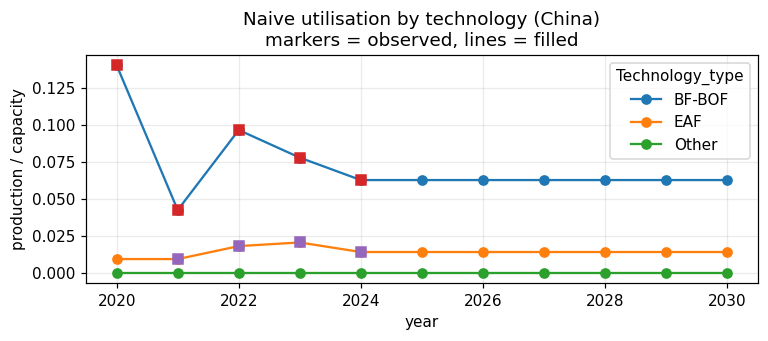

In [5]:
TECHS = ["BF-BOF", "EAF", "Other"]


def classify_technology(equipment):
    """BF-BOF if any blast-furnace / basic-oxygen unit, else EAF, else Other."""
    if not isinstance(equipment, str):
        return "Other"
    parts = {p.strip().upper() for p in equipment.split(";")}
    if "BF" in parts or "BOF" in parts:
        return "BF-BOF"
    if "EAF" in parts:
        return "EAF"
    return "Other"


china_operational["Technology_type"] = china_operational["Main production equipment"].map(classify_technology)
crude_steel["Technology_type"] = crude_steel["Main production equipment"].map(classify_technology)

china_capacity_by_tech = (china_operational
                          .pivot_table(index="Year", columns="Technology_type", values=CAP, aggfunc="sum")
                          .reindex(columns=TECHS).fillna(0.0))

china_production_by_tech = (crude_steel[crude_steel["Country/Area"] == "China"]
                            .pivot_table(index="Year", columns="Technology_type",
                                         values="Production_ttpa", aggfunc="sum")
                            .reindex(columns=TECHS))

utilization_by_tech = (china_production_by_tech / china_capacity_by_tech).reindex(years)

# Years without reported production get the last observed rate (and the pooled
# rate of the technology if nothing was ever observed).
pooled_naive = (china_production_by_tech.sum() / china_capacity_by_tech.sum()).reindex(TECHS)
utilization_by_tech_filled = (utilization_by_tech.ffill().bfill()
                              .fillna(pooled_naive.fillna(0.0)))

with pd.option_context("display.float_format", "{:.4f}".format):
    print("capacity by technology (Mt)"); print((china_capacity_by_tech / 1000).head(3).round(1), "\n")
    print("utilization_by_tech (naive, Part A)"); print(utilization_by_tech, "\n")
    print("utilization_by_tech_filled"); print(utilization_by_tech_filled)

ax = utilization_by_tech_filled.plot(marker="o", figsize=(7, 3.2))
utilization_by_tech.plot(ax=ax, marker="s", linestyle="none", legend=False)
ax.set(title="Naive utilisation by technology (China)\nmarkers = observed, lines = filled",
       ylabel="production / capacity", xlabel="year")
plt.tight_layout(); plt.show()

## A4. Plant-level production

**Goal.** Attribute each technology's utilisation rate to its plants: add `Utilization_rate_tech` and `Estimated_production_ttpa` (= capacity x utilisation) to `china_operational`.

In [6]:
util_lookup = utilization_by_tech_filled.stack()          # (Year, Technology) -> rate

china_operational["Utilization_rate_tech"] = pd.MultiIndex.from_arrays(
    [china_operational["Year"], china_operational["Technology_type"]]).map(util_lookup)

china_operational["Estimated_production_ttpa"] = (china_operational[CAP].fillna(0.0)
                                                  * china_operational["Utilization_rate_tech"])

print(china_operational.groupby("Year")["Estimated_production_ttpa"].sum() / 1000, "\n(Mt)\n")
china_operational[["Plant ID", "Year", "Status", "Main production equipment", "Technology_type",
                   CAP, "Utilization_rate_tech", "Estimated_production_ttpa"]].head()

Year
2020   178.69
2021    54.82
2022   122.75
2023    97.07
2024    77.20
2025    77.06
2026    76.94
2027    76.80
2028    76.80
2029    76.80
2030    76.80
Name: Estimated_production_ttpa, dtype: float64 
(Mt)



,Plant ID,Year,Status,Main production equipment,Technology_type,Nominal crude steel capacity (ttpa),Utilization_rate_tech,Estimated_production_ttpa
44,P100000120284,2020,retired,BF,BF-BOF,NaN,0.14,0.00
45,P100000120284,2021,retired,BF,BF-BOF,NaN,0.04,0.00
46,P100000120284,2022,retired,BF,BF-BOF,NaN,0.10,0.00
47,P100000120284,2023,retired,BF,BF-BOF,NaN,0.08,0.00
48,P100000120284,2024,retired,BF,BF-BOF,NaN,0.06,0.00


## A5. Emission factors and plant emissions

**Goal.** Create `emission_factors` (dict), `map_emission_factor` (function), and add `Emission_factor_tCO2_per_t` and `Estimated_emissions_tCO2` to `china_operational`.

Use these emissions factors (tCO2 per tonne crude steel, after Hasanbeigi 2019), keyed by the **exact** equipment string, with **1.6** for anything else:

| `BF; BOF` 2.1 | `BF; BOF; EAF` 1.9 | `BF; BOF; EAF; DRI` 1.9 | `BF; BOF; DRI` 2.0 | `BF; EAF` 1.9 |
|---|---|---|---|---|
| `BF` 2.2 | `EAF` 0.4 | `EAF; DRI` 1.2 | `DRI` 1.3 | `Steel other/unspecified` 1.6 |

> **Hint.** Emissions (t) = production (ttpa) x 1,000 x factor. `Series.map` with a function, or `dict.get(key, 1.6)`.

In [7]:
emission_factors = {
    "BF; BOF": 2.1, "BF; BOF; EAF": 1.9, "BF; BOF; EAF; DRI": 1.9, "BF; BOF; DRI": 2.0,
    "BF; EAF": 1.9, "BF": 2.2, "EAF": 0.4, "EAF; DRI": 1.2, "DRI": 1.3,
    "Steel other/unspecified": 1.6,
}
DEFAULT_EF = 1.6

# The June 2026 release lists the units in alphabetical order ("DRI; EAF"), while the
# table above was written for the September 2025 order ("EAF; DRI"). A strict string
# match would silently send every DRI;EAF plant to the 1.6 default, so we fall back to
# a match on the *set* of units before giving up.
_ef_by_unit_set = {frozenset(k.split("; ")): v for k, v in emission_factors.items()}


def map_emission_factor(equipment):
    if not isinstance(equipment, str):
        return DEFAULT_EF
    if equipment in emission_factors:
        return emission_factors[equipment]
    return _ef_by_unit_set.get(frozenset(p.strip() for p in equipment.split(";")), DEFAULT_EF)


china_operational["Emission_factor_tCO2_per_t"] = (china_operational["Main production equipment"]
                                                   .map(map_emission_factor))
china_operational["Estimated_emissions_tCO2"] = (china_operational["Estimated_production_ttpa"] * 1_000
                                                 * china_operational["Emission_factor_tCO2_per_t"])

print("emission factor used, by number of distinct plant/equipment combinations:")
print(china_operational.drop_duplicates(["Plant ID", "Main production equipment"])
      ["Emission_factor_tCO2_per_t"].value_counts().sort_index(), "\n")
print("national emissions, Part A (MtCO2):")
print(china_operational.groupby("Year")["Estimated_emissions_tCO2"].sum() / 1e6)

emission factor used, by number of distinct plant/equipment combinations:
Emission_factor_tCO2_per_t
0.40    152
1.20      2
1.30      3
1.60     41
1.90     57
2.00      2
2.10    250
2.20     72
Name: count, dtype: int64 

national emissions, Part A (MtCO2):
Year
2020   357.60
2021   107.74
2022   242.09
2023   189.24
2024   151.23
2025   150.92
2026   150.58
2027   150.27
2028   150.27
2029   150.27
2030   150.27
Name: Estimated_emissions_tCO2, dtype: float64


## A6. Company emissions

**Goal.** Create `Company` (= `Parent`, or `Owner` when `Parent` is missing), `company_emissions` (columns `Year`, `Company`, `estimated_emissions_tCO2`) and `top_companies_latest` (top 10 in the **latest year**).

distinct companies: 389  |  latest year: 2030



,Year,Company,estimated_emissions_tCO2
0,2030,Angang Steel Co Ltd [100.0%],"4,335,663.82"
1,2030,Baoshan Iron & Steel Co Ltd [100.0%],"4,086,977.76"
2,2030,Jinghua Rigang Holding Group Co Ltd [98.8%]; u...,"2,980,239.05"
3,2030,Beijing Shougang Co Ltd [100.0%],"2,845,640.40"
4,2030,Jiangsu Shagang Iron & Steel Co Ltd [100.0%],"2,484,631.45"
5,2030,Maanshan Iron & Steel Co Ltd [100.0%],"2,381,428.27"
6,2030,Jingye Group Co Ltd [100.0%],"2,322,118.62"
7,2030,Inner Mongolia BaoTou Steel Union Co Ltd [100.0%],"2,305,069.85"
8,2030,British Asia Pan Ruogen International Co Ltd [...,"2,238,695.79"
9,2030,Guangxi Shenglong Metallurgical Co Ltd [100.0%],"2,201,854.11"


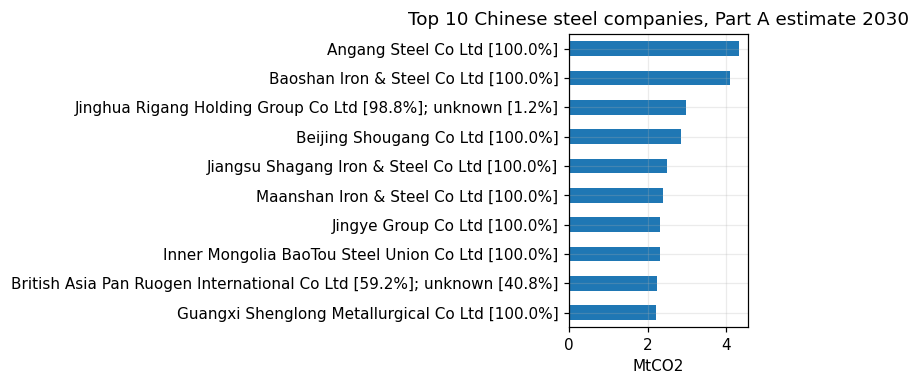

In [8]:
china_operational = china_operational.merge(plant_data[["Plant ID", "Owner", "Parent"]],
                                           on="Plant ID", how="left")


def _clean_name(x):
    s = str(x).strip()
    return None if (not s or s.lower() in {"nan", "unknown", "none"}) else s


# Company = Parent, or Owner when Parent is missing. We keep the raw GIST string
# (including the "[xx%]" share tags) - Q2 is about exactly those strings.
china_operational["Company"] = [_clean_name(p) or _clean_name(o) or "Unknown"
                                for p, o in zip(china_operational["Parent"], china_operational["Owner"])]

company_emissions = (china_operational
                     .groupby(["Year", "Company"], as_index=False)["Estimated_emissions_tCO2"].sum()
                     .rename(columns={"Estimated_emissions_tCO2": "estimated_emissions_tCO2"}))

latest_year = int(company_emissions["Year"].max())
top_companies_latest = (company_emissions[company_emissions["Year"] == latest_year]
                        .nlargest(10, "estimated_emissions_tCO2")
                        .reset_index(drop=True))

print(f"distinct companies: {company_emissions['Company'].nunique()}  |  latest year: {latest_year}\n")
display(top_companies_latest)

ax = (top_companies_latest.set_index("Company")["estimated_emissions_tCO2"] / 1e6).iloc[::-1].plot(
    kind="barh", figsize=(7, 3.6))
ax.set(title=f"Top 10 Chinese steel companies, Part A estimate {latest_year}", xlabel="MtCO2", ylabel="")
plt.tight_layout(); plt.show()

### Q2 [QUAL] Look at the company names

Read the names in `top_companies_latest`. Give **two data-quality problems** you notice, and explain how each could bias a *financed-emissions* figure for a lender (hint: ownership shares, joint ventures).

**Your answer (Q2):**

**1. `Parent` is a free-text ownership *string*, not an entity with a share.** The names in
`top_companies_latest` read `Jinghua Rigang Holding Group Co Ltd [98.8%]; unknown [1.2%]` and
`British Asia Pan Ruogen International Co Ltd [59.2%]; unknown [40.8%]`. 194 of the 458 Chinese
plants list several parents in one cell and 121 contain an `unknown` slice. Our pipeline groups on
that raw string, so it books **100% of a plant's emissions against a parent that may only own 59%**,
and every distinct share combination becomes a different "company". A lender computes financed
emissions as *its share of the borrower x the borrower's share of the asset*; attributing the whole
plant to one joint-venture partner **over-states** that borrower's financed emissions, while the
`unknown` slices (up to 40.8% of a plant) are never attributed to anybody and simply disappear from
any market-wide total.

**2. The same corporate group is split across many rows, and listed subsidiaries stand in for the
ultimate parent.** `China Baowu Steel Group Co Ltd` appears under **seven** different parent strings
(100%, 79.3%, 75%, 70%, 48.4%, 27.7% ...), `Ansteel Group Co Ltd` under three, `Jinghua Rigang` under
three; and the top of our table shows the *listed* vehicles `Angang Steel Co Ltd` and
`Baoshan Iron & Steel Co Ltd` rather than their real parents Ansteel Group and China Baowu. A bank
usually lends to, or holds bonds of, the **group**. Because the group's emissions are scattered over
several rows, group-level exposure is **under-stated**, concentration limits are never triggered, and
the same tonne of CO2 can be double-counted if the bank separately finances the listed subsidiary and
the group. A proper figure needs the names resolved to a single legal-entity identifier (GEM entity
ID / PermID) and the percentages parsed into real ownership weights.


## A7. Projection to 2030

**Goal.** Create `actual_years` (years with production data), `forecast_years` (the years after the last observed one), `projected_company_emissions` (company emissions in the forecast years) and a function `top_company_emissions(df, year)` returning the top 5 companies of that year. Print the top 5 for the first three forecast years.

actual_years  : [2020, 2021, 2022, 2023, 2024]
forecast_years: [2025, 2026, 2027, 2028, 2029, 2030] 

--- top 5 in 2025 ---


,Company,MtCO2
0,Angang Steel Co Ltd [100.0%],4.34
1,Baoshan Iron & Steel Co Ltd [100.0%],4.09
2,Jinghua Rigang Holding Group Co Ltd [98.8%]; u...,2.98
3,Beijing Shougang Co Ltd [100.0%],2.84
4,Jiangsu Shagang Iron & Steel Co Ltd [100.0%],2.48



--- top 5 in 2026 ---


,Company,MtCO2
0,Angang Steel Co Ltd [100.0%],4.34
1,Baoshan Iron & Steel Co Ltd [100.0%],4.09
2,Jinghua Rigang Holding Group Co Ltd [98.8%]; u...,2.98
3,Beijing Shougang Co Ltd [100.0%],2.85
4,Jiangsu Shagang Iron & Steel Co Ltd [100.0%],2.48



--- top 5 in 2027 ---


,Company,MtCO2
0,Angang Steel Co Ltd [100.0%],4.34
1,Baoshan Iron & Steel Co Ltd [100.0%],4.09
2,Jinghua Rigang Holding Group Co Ltd [98.8%]; u...,2.98
3,Beijing Shougang Co Ltd [100.0%],2.85
4,Jiangsu Shagang Iron & Steel Co Ltd [100.0%],2.48


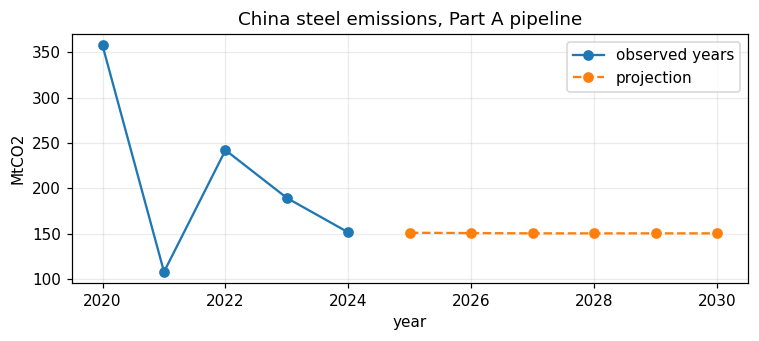

In [9]:
actual_years = [y for y in years if china_production.get(y, 0) > 0]
last_actual_year = max(actual_years)
forecast_years = [y for y in years if y > last_actual_year]

projected_company_emissions = company_emissions[company_emissions["Year"].isin(forecast_years)].copy()


def top_company_emissions(df, year, n=5):
    """Top n companies of `year` in a (Year, Company, estimated_emissions_tCO2) frame."""
    return (df[df["Year"] == year]
            .nlargest(n, "estimated_emissions_tCO2")
            .assign(MtCO2=lambda d: d["estimated_emissions_tCO2"] / 1e6)
            .loc[:, ["Company", "MtCO2"]]
            .reset_index(drop=True))


print("actual_years  :", actual_years)
print("forecast_years:", forecast_years, "\n")

for y in forecast_years[:3]:
    print(f"--- top 5 in {y} ---")
    display(top_company_emissions(projected_company_emissions, y))
    print()

national = company_emissions.groupby("Year")["estimated_emissions_tCO2"].sum() / 1e6
ax = national.loc[actual_years].plot(marker="o", figsize=(7, 3.2), label="observed years")
national.loc[forecast_years].plot(ax=ax, marker="o", linestyle="--", label="projection")
ax.set(title="China steel emissions, Part A pipeline", ylabel="MtCO2", xlabel="year")
ax.legend(); plt.tight_layout(); plt.show()

### Q3 [QUAL] Forecast, projection or scenario?

The top-5 tables for the first projected years are (almost) identical. (a) Why? (b) Is this a **forecast**, a **projection** or a **scenario**, and what is it conditional on? (c) Name **three things** a fan chart would tell a risk manager that this table does not.

**Your answer (Q3):**

**(a) Why are they identical?** After 2024 (the last year with reported production) nothing in the
calculation moves any more. `utilization_by_tech_filled` forward-fills the 2024 rate, so every year
2025-2030 uses the same BF-BOF rate (0.063) and EAF rate (0.014); capacity changes only for the
handful of plants whose start or retirement date falls inside the window (China's total moves from
1,375.7 Mt in 2025 to 1,375.3 Mt in 2030, i.e. -0.03%); and the emission factors are constants. Each
company's emissions are therefore frozen at their 2024-derived level, so both the values and the
ranking repeat. National emissions go from 150.92 MtCO2 in 2025 to 150.27 in 2030.

**(b) Forecast, projection or scenario?** It is a **projection** - a mechanical extension of today's
plant list under fixed assumptions, not a best estimate of what will happen (forecast) and not an
explicit "what if" story (scenario). It is conditional on: the GIST capacity list being complete and
correct; no plants being built, retired or mothballed beyond the dates already recorded; utilisation
staying at its last observed (and badly biased, see B1) level; fixed Hasanbeigi emission factors with
no technology improvement; and the current ownership structure.

**(c) Three things a fan chart would add.**
1. **How wide the plausible range is in each year** - our own simulation puts 2030 between 1,762 and
   2,243 MtCO2, so "the" number is really +/-12%; a single table hides that completely.
2. **Whether the uncertainty grows with the horizon** - a flat line of point estimates suggests 2030
   is known as well as 2025, which is false; a fan that widens tells the risk manager when the
   estimate stops being usable.
3. **The probability of crossing a threshold** - e.g. "what is the chance 2030 emissions exceed the
   2023 level, or a transition-risk budget?" (Q13 gives 45% in the baseline). A point table can never
   answer a probability question, and it cannot show that the gap between the #1 and #2 company is
   smaller than the uncertainty on either of them.


---
# PART B. How much can we trust these numbers?

You now have company emissions as **single numbers**. Part B asks three simple questions:

1. **Do the numbers agree with an outside reference?** (reality check)
2. **How wide is the range of plausible values?** (an interval, found by simulation)
3. **What does the range depend on?** (inputs and scenarios)

**Three words you need**

| Word | Meaning | Example |
|---|---|---|
| **Aleatoric** uncertainty | pure randomness, more data does *not* remove it | will a given year be a strong or a weak year for steel? |
| **Epistemic** uncertainty | we lack knowledge, more data or better models *can* reduce it | what is the true average emission factor of a blast furnace? |
| **Scenario** uncertainty | depends on future choices, it is not a probability | will China retire old blast furnaces by 2030? |

A **90% interval** is a range that contains the true value in 90% of cases *if our assumptions are right*.

## B0. Think first

> **Pause & think.** No code.

### Q4 [QUAL] Which kind of uncertainty?

For each input of your pipeline, write **A** (aleatoric), **E** (epistemic) or **S** (scenario), and say whether **more data could reduce it** (yes / no). One short line each.

| Input | A / E / S | More data helps? |
|---|---|---|
| Utilisation rate of a blast furnace next year | | |
| Emission factor of BF-BOF steel | | |
| Share of plants that report their production | | |
| Steel demand in 2030 | | |

**Your answer (Q4):**

| Input | A / E / S | More data helps? |
|---|---|---|
| Utilisation rate of a blast furnace next year | **A** | **No** - a furnace's load next year depends on demand, maintenance and outages; more history lets us estimate the *distribution* better, but the year-to-year randomness itself never disappears. |
| Emission factor of BF-BOF steel | **E** | **Yes** - there is one true average intensity for a given fleet; plant-level energy and material balances, audited disclosures or measurements shrink the range (it is the biggest driver of our interval, Q9). |
| Share of plants that report their production | **E** | **Yes** - this is a property of the *dataset*, not of the world; better collection, mandatory disclosure or satellite/trade cross-checks raise coverage from today's 9.5% (Q5). |
| Steel demand in 2030 | **S** | **No** - it depends on policy, construction activity and trade decisions that have not been made yet; it is a choice to be explored with scenarios, not a quantity to be estimated with a probability. |


## B1. Reality check against official statistics

Official crude steel production of China (**rounded worldsteel figures: verify them and cite your source**):

| Year | 2020 | 2021 | 2022 | 2023 |
|---|---|---|---|---|
| Mt | 1,065 | 1,035 | 1,015 | 1,020 |

**Goal.** Create `official_kt` (dict, in **ttpa**: 1 Mt = 1,000 ttpa) and a DataFrame `check` with, for 2020-2023: the production in your dataset (`china_production`), the official value, the **coverage** (dataset / official) and the **implied utilisation** (official / `china_capacity`).

> **Hint.** `pd.Series(official_kt)`, `pd.DataFrame({...})`, `.dropna()`.

,dataset_ttpa,official_ttpa,coverage,implied_utilisation
2020,"177,048.0000",1065000,0.1662,0.7412
2021,"54,817.0000",1035000,0.0530,0.7217
2022,"122,752.0000",1015000,0.1209,0.7151
2023,"97,068.0000",1020000,0.0952,0.7360


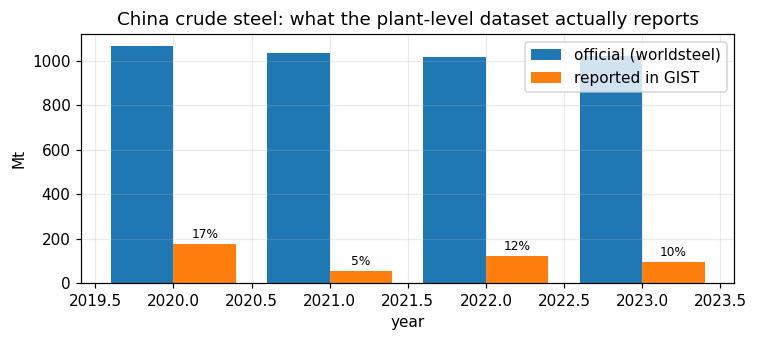

In [10]:
# worldsteel, crude steel production of China (Mt):
#   2020 1,064.8 | 2021 1,035.2 | 2022 1,018.0 | 2023 1,019.1 (later revised to 1,028.9)
# Source: World Steel Association, "World Steel in Figures 2024" and "World Steel in
# Figures 2025", table "Top steel-producing countries"; worldsteel December press
# releases for the annual totals. The rounded values in the lab table agree within ~1%.
official_mt = {2020: 1065, 2021: 1035, 2022: 1015, 2023: 1020}
official_kt = {y: v * 1_000 for y, v in official_mt.items()}        # 1 Mt = 1,000 ttpa

check = pd.DataFrame({"dataset_ttpa": china_production.reindex(official_kt),
                      "official_ttpa": pd.Series(official_kt)}).dropna()
check["coverage"] = check["dataset_ttpa"] / check["official_ttpa"]
check["implied_utilisation"] = check["official_ttpa"] / china_capacity.reindex(check.index)

with pd.option_context("display.float_format", "{:,.4f}".format):
    display(check)

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.bar(check.index - 0.2, check["official_ttpa"] / 1000, width=0.4, label="official (worldsteel)")
ax.bar(check.index + 0.2, check["dataset_ttpa"] / 1000, width=0.4, label="reported in GIST")
for y in check.index:
    ax.text(y + 0.2, check.loc[y, "dataset_ttpa"] / 1000 + 25,
            f"{check.loc[y, 'coverage']:.0%}", ha="center", fontsize=8)
ax.set(title="China crude steel: what the plant-level dataset actually reports",
       ylabel="Mt", xlabel="year"); ax.legend()
plt.tight_layout(); plt.show()

### Q5 [QUANT + QUAL] What does your pipeline miss?

(a) Give the **coverage** and **implied utilisation** for 2023, and the factor by which your Part A pipeline **under-estimates** China's production. (b) The BF-BOF "utilisation" in Part A drops from about 57% to about 8% between 2020 and 2021. Is that a real change in how furnaces are run, or something else? Which kind of uncertainty is it (A, E or S)?

**Your answer (Q5):**

**(a) 2023.** Coverage = 97,068 / 1,020,000 = **0.0952, i.e. 9.5%**. Implied utilisation =
1,020,000 / 1,385,866 = **0.736 (73.6%)**. The Part A pipeline therefore under-estimates China's
crude steel production by a factor of **1 / 0.0952 = 10.5x** (97.1 Mt instead of 1,020 Mt). Coverage
is never better than 17% in any year (2020: 16.6%, 2021: 5.3%, 2022: 12.1%, 2023: 9.5%).

**(b) The drop is an artefact, not a change in how furnaces are run.** The number of Chinese plants
that report a crude steel figure collapses from **35 in 2020 to 15 in 2021** (177.0 Mt to 54.8 Mt),
while the denominator - the whole fleet's capacity - barely moves (1,436.9 to 1,434.1 Mt). We are
dividing a shrinking, changing *sample* by a constant *population*, so the ratio is a reporting-rate
indicator, not a utilisation rate. (In our June 2026 release the naive BF-BOF rate falls from
**14.0% to 4.2%**; the lab text quotes 57% to 8% from the September 2025 release - the same artefact,
a different reporting sample.) Meanwhile the utilisation implied by the official statistics stays
flat at 74.1%, 72.2%, 71.5%, 73.6% - no real change at all.

This is **epistemic (E)** uncertainty: it is a gap in our knowledge of who reports, and it would
disappear with complete reporting. It is also a *bias*, not noise - it always pushes the estimate
down, so no amount of averaging fixes it.


## B2. Fix the denominator: compare like with like

Use only plants that **report production** *and* have a capacity ("matched" plants), so that numerator and denominator describe the same plants.

**Goal.** Create `obs_matched` (one row per plant-year with production **and** capacity > 0, with `Technology_type` and `u` = production / capacity) and `utilization_matched` (year x technology: **sum of production / sum of capacity** of the matched plants).

> **Hint.** Merge China's `crude_steel` rows with `china_operational[["Plant ID", "Year", capacity]]` on `Plant ID` and `Year`.

In [11]:
# One capacity number per (plant, year): sum the status phases of the plant.
capacity_plant_year = china_operational.groupby(["Plant ID", "Year"], as_index=False)[CAP].sum()

obs_matched = (crude_steel.loc[crude_steel["Country/Area"] == "China",
                               ["Plant ID", "Year", "Production_ttpa", "Technology_type"]]
               .merge(capacity_plant_year, on=["Plant ID", "Year"], how="inner"))
obs_matched = obs_matched[(obs_matched[CAP] > 0) & (obs_matched["Production_ttpa"] > 0)].copy()
obs_matched["u"] = obs_matched["Production_ttpa"] / obs_matched[CAP]

utilization_matched = (obs_matched.groupby(["Year", "Technology_type"])
                       .apply(lambda d: d["Production_ttpa"].sum() / d[CAP].sum())
                       .unstack())

print("matched plant-years:", len(obs_matched),
      "| distinct plants:", obs_matched["Plant ID"].nunique(),
      "| plants per technology:",
      obs_matched.groupby("Technology_type")["Plant ID"].nunique().to_dict(), "\n")
print("utilization_matched (sum production / sum capacity of the matched plants)")
with pd.option_context("display.float_format", "{:.4f}".format):
    display(utilization_matched)
    print("\nspread of the plant-level rate u across the matched plant-years:")
    display(obs_matched["u"].describe().to_frame().T)

matched plant-years: 103 | distinct plants: 66 | plants per technology: {'BF-BOF': 59, 'EAF': 7} 

utilization_matched (sum production / sum capacity of the matched plants)


Technology_type,BF-BOF,EAF
Year,,
2020,0.8104,NaN
2021,0.7216,0.6437
2022,0.8303,0.8320
2023,0.7658,0.6242
2024,0.8034,0.7539



spread of the plant-level rate u across the matched plant-years:


,count,mean,std,min,25%,50%,75%,max
u,103.0000,0.7958,0.1992,0.2922,0.6853,0.8009,0.9415,1.5190


### Q6 [QUANT + QUAL] Naive or matched?

(a) For **BF-BOF in 2023**, report the Part A (naive) utilisation, the matched utilisation, and the official-implied utilisation (from `check`). (b) Which would you use for projections? In one sentence, say what bias could **remain** in the matched estimate (hint: which plants report their production?).

**Your answer (Q6):**

**(a) BF-BOF, 2023.**

| estimate | value |
|---|---|
| Part A, naive (all reported production / all capacity) | **0.078** |
| matched (reporting plants only, both sides) | **0.766** |
| official-implied (worldsteel / total capacity, from `check`) | **0.736** |

The naive rate is wrong by a factor of ten; the matched rate lands within 4% of the official-implied
one, even though it never uses the official statistics.

**(b) Which one, and what bias remains?** Use the **matched** rate: numerator and denominator then
describe the same plants, so it measures utilisation instead of measuring reporting coverage. The
bias that remains is **selection bias in who reports**: only 59 of China's ~390 BF-BOF plants publish
production, and those are the large, listed, modern, well-utilised ones (the plant-level rate `u`
ranges from 0.29 to 1.52 across the 103 matched plant-years), so the matched rate is probably a
little **above** the true fleet average - which is exactly the direction of the 0.766 vs 0.736 gap,
and the reason our simulation over-shoots official 2023 output in Q11.


## B3. A range from a sample: the bootstrap

We have a matched utilisation for BF-BOF, but it comes from a **sample** of plants. A different sample would give a slightly different value. How different? The **bootstrap** answers it in four steps:

1. Draw plants **with replacement** from your sample, as many as the sample contains.
2. Recompute the average utilisation (sum of production / sum of capacity).
3. Repeat **1,000 times**.
4. The 5th and 95th percentiles of the 1,000 values form a **90% interval**.

**Goal.** Write a function `boot_mean_u(df, n=1000)` that returns the `n` bootstrap values. Use it to create `ci_all` (interval for **all** matched BF-BOF plants) and `ci_small` (interval for **10 randomly chosen** BF-BOF plants).

> **Hint.** Sum production and capacity **per plant** first (`groupby("Plant ID")`), then resample plant numbers with `np.random.default_rng(42).integers(0, n_plants, size=(n, n_plants))`; the values of one draw are `prod[idx].sum(1) / cap[idx].sum(1)`. `np.percentile(values, [5, 95])`.

all matched BF-BOF plants (n = 59): point 0.795  90% CI [0.763, 0.831]  width 0.068
10 random BF-BOF plants            : point 0.809  90% CI [0.729, 0.914]  width 0.184
the small-sample interval is 2.7x wider


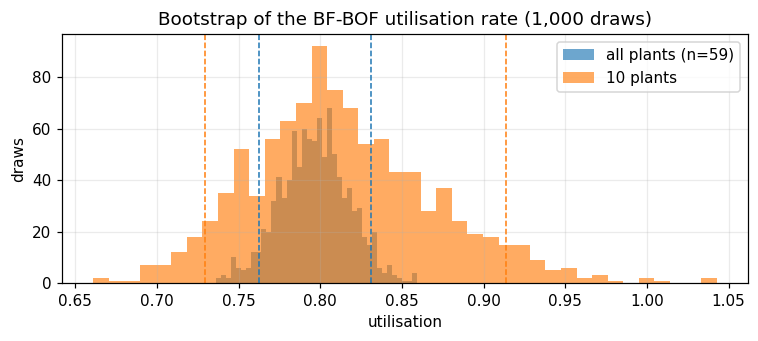

In [12]:
def boot_mean_u(df, n=1000, seed=SEED):
    """n bootstrap values of sum(production)/sum(capacity), resampling PLANTS."""
    g = df.groupby("Plant ID")[["Production_ttpa", CAP]].sum()
    prod = g["Production_ttpa"].to_numpy(float)
    cap = g[CAP].to_numpy(float)
    k = len(g)
    if k == 0:
        return np.array([])
    idx = np.random.default_rng(seed).integers(0, k, size=(n, k))
    return prod[idx].sum(1) / cap[idx].sum(1)


bf_matched = obs_matched[obs_matched["Technology_type"] == "BF-BOF"]

boot_all = boot_mean_u(bf_matched, n=1000)
ci_all = np.percentile(boot_all, [5, 95])

rng = np.random.default_rng(SEED)
small_ids = rng.choice(bf_matched["Plant ID"].unique(), size=10, replace=False)
bf_small = bf_matched[bf_matched["Plant ID"].isin(small_ids)]
boot_small = boot_mean_u(bf_small, n=1000)
ci_small = np.percentile(boot_small, [5, 95])

print(f"all matched BF-BOF plants (n = {bf_matched['Plant ID'].nunique()}): "
      f"point {bf_matched['Production_ttpa'].sum() / bf_matched[CAP].sum():.3f}  "
      f"90% CI [{ci_all[0]:.3f}, {ci_all[1]:.3f}]  width {ci_all[1] - ci_all[0]:.3f}")
print(f"10 random BF-BOF plants            : point "
      f"{bf_small['Production_ttpa'].sum() / bf_small[CAP].sum():.3f}  "
      f"90% CI [{ci_small[0]:.3f}, {ci_small[1]:.3f}]  width {ci_small[1] - ci_small[0]:.3f}")
print(f"the small-sample interval is {(ci_small[1] - ci_small[0]) / (ci_all[1] - ci_all[0]):.1f}x wider")

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.hist(boot_all, bins=40, alpha=0.65, label=f"all plants (n={bf_matched['Plant ID'].nunique()})")
ax.hist(boot_small, bins=40, alpha=0.65, label="10 plants")
for c, col in [(ci_all, "tab:blue"), (ci_small, "tab:orange")]:
    for v in c:
        ax.axvline(v, color=col, linestyle="--", linewidth=1)
ax.set(title="Bootstrap of the BF-BOF utilisation rate (1,000 draws)",
       xlabel="utilisation", ylabel="draws"); ax.legend()
plt.tight_layout(); plt.show()

### Q7 [QUANT + QUAL] Small sample, wide interval

(a) Report `ci_all` and `ci_small` and their widths. (b) Why is the second wider? (c) In one sentence, what does "90% interval" mean here? (d) Which kind of uncertainty (A or E) shrinks when you have more plants?

**Your answer (Q7):**

**(a)**

| sample | point estimate | 90% interval | width |
|---|---|---|---|
| `ci_all` - all 59 matched BF-BOF plants | 0.795 | **[0.763, 0.831]** | **0.068** |
| `ci_small` - 10 randomly chosen plants | 0.809 | **[0.729, 0.914]** | **0.184** |

The small-sample interval is **2.7x wider**.

**(b) Why is the second wider?** With only 10 plants, each bootstrap resample is dominated by whichever
few large plants happen to be drawn, so the recomputed ratio swings much more from draw to draw. The
sampling error of a mean falls roughly like 1/sqrt(n), and sqrt(59/10) = 2.4, which is almost exactly
the 2.7x we observe (the rest comes from the capacity weighting: the ratio is driven by a handful of
very large plants).

**(c) What does "90% interval" mean here?** If we repeated the whole exercise many times - drawing a
new sample of plants from the same population of reporting BF-BOF plants and recomputing the interval
each time - about 90 out of 100 of those intervals would contain the true capacity-weighted average
utilisation **of that population**. It is a statement about the procedure, not about this one
interval, and it says nothing about plants outside the population we sampled from (see Q6b and Q11).

**(d) Which uncertainty shrinks with more plants?** **Epistemic (E)**. More plants tell us more about
the one fixed quantity we are trying to pin down, so the interval narrows towards zero width. The
aleatoric part - the fact that any single furnace has a good year or a bad year - does not shrink; it
stays as the spread of `u` across plants and years (sd = 0.20).


> ### [OPTIONAL] Bayesian version of the same interval
>
> A **credible interval** answers a more direct question: *given the data and what I believed before, where is the true average?* We start from a **prior guess** (mean $\mu_0$, worth $\kappa_0$ observations) and update it with the data (mean $\bar x$, $n$ observations):
>
> posterior mean $=\dfrac{\kappa_0\,\mu_0 + n\,\bar x}{\kappa_0+n}$ (a weighted average: the prior counts as $\kappa_0$ observations).
>
> **Task.** For the **10 plants** of `ci_small`, compute the posterior mean for (i) a **weak** prior ($\mu_0=0.5$, $\kappa_0=0.01$) and (ii) a **wrong** prior ($\mu_0=0.3$, $\kappa_0=5$). The width of a 90% interval is roughly $1.8\times s/\sqrt{n+\kappa_0}$ ($s$ = standard deviation of the 10 values).
> **Question Q7b.** How much does the wrong prior move the answer, and why does this matter when data are scarce?

In [13]:
# Plant-level rates of the 10 plants used for ci_small
g_small = bf_small.groupby("Plant ID")[["Production_ttpa", CAP]].sum()
x_small = (g_small["Production_ttpa"] / g_small[CAP]).to_numpy()
x_bar, s_small, n_small = x_small.mean(), x_small.std(ddof=1), len(x_small)

rows = []
for name, (mu0, kappa0) in {"weak prior (0.50, k=0.01)": (0.5, 0.01),
                            "wrong prior (0.30, k=5)": (0.3, 5.0)}.items():
    post = (kappa0 * mu0 + n_small * x_bar) / (kappa0 + n_small)
    half = 1.8 * s_small / np.sqrt(n_small + kappa0) / 2
    rows.append({"prior": name, "posterior_mean": post,
                 "90% CI low": post - half, "90% CI high": post + half,
                 "shift vs data mean": post - x_bar})

print(f"data: mean of the 10 plant rates = {x_bar:.4f}, s = {s_small:.4f}, n = {n_small}\n")
display(pd.DataFrame(rows).set_index("prior"))

data: mean of the 10 plant rates = 0.8474, s = 0.1845, n = 10



,posterior_mean,90% CI low,90% CI high,shift vs data mean
prior,,,,
"weak prior (0.50, k=0.01)",0.85,0.79,0.90,-0.00
"wrong prior (0.30, k=5)",0.66,0.62,0.71,-0.18


**Your answer (Q7b (optional)):**

The 10 plants give x-bar = 0.8474, s = 0.1845, n = 10.

| prior | posterior mean | ~90% interval | shift vs data mean |
|---|---|---|---|
| weak: mu0 = 0.50, kappa0 = 0.01 | **0.8471** | [0.795, 0.899] | -0.0003 |
| wrong: mu0 = 0.30, kappa0 = 5 | **0.6650** | [0.622, 0.708] | **-0.1824** |

The weak prior is worth one hundredth of an observation, so it moves the answer by 0.0003 - nothing.
The wrong prior is worth 5 observations against only 10 real ones, so it carries a third of the weight
and drags the estimate down by **0.18, i.e. 22% below the data**, to a value (0.665) that **no plant in
the sample is anywhere near** and that the 90% interval of the data alone excludes.

Why it matters when data are scarce: the prior's influence is kappa0 / (kappa0 + n), so with n = 10 a
modest-looking prior still rewrites the result, while with n = 59 (our full sample) the same prior
would move it by less than 0.03. A 22% error on utilisation feeds straight through to a 22% error on
a company's estimated emissions - entirely from an assumption, with no new evidence behind it. So with
small samples the prior must be justified from real evidence (a published technical average, not a
round number) and every published figure should be re-run under at least one alternative prior.


## B4. Simulation: a range for emissions

**Idea (Monte Carlo).** Instead of one value per input, use a *plausible range*, then **repeat the whole calculation many times**, each time with different plausible values. The cloud of results shows the uncertainty of the output.

Two uncertain inputs:

| Input | Plausible range | How to draw |
|---|---|---|
| **Utilisation** per technology | the bootstrap values of B3 | one bootstrap value per draw and technology (all technologies pooled if a technology has fewer than 5 plants) |
| **Emission factor** per technology | multiplier on your Part A factor, **assumed illustrative values** below | triangular distribution (low, mode = 1, high): `rng.triangular(low, 1, high, size=n)` |

| Technology | low | mode | high |
|---|---|---|---|
| BF-BOF | 0.85 | 1 | 1.20 |
| EAF | 0.65 | 1 | 2.00 |
| Other | 0.65 | 1 | 1.40 |

**Goal.** Create `ef_mult_ranges` (dict) and a function `simulate(n=1000, year=2030, vary_util=True, vary_ef=True, bf_cap_mult=1.0, util_mult=1.0, seed=0)` returning a dict with
* `national`: array of `n` national emissions (**MtCO2**) for `year`;
* `national_prod`: array of `n` national productions (**Mt**);
* `by_company`: DataFrame (`n` rows, one column per company, MtCO2).

> **Hint.**
> 1. Take the rows of `china_operational` for `year`. For every plant you need: capacity (missing = 0), technology, your Part A emission factor, company.
> 2. Draw a matrix `u` (n x 3) of utilisations and a matrix `mult` (n x 3) of multipliers (columns = BF-BOF, EAF, Other). If `vary_util=False`, use the pooled matched utilisation of each technology instead (sum of production / sum of capacity over all years); if `vary_ef=False`, use multipliers equal to 1.
> 3. Choose each plant's column by its technology: `u[:, tech_index_of_plant]` gives an (n x plants) matrix. Then production = capacity x utilisation (x `util_mult`), emissions = production x 1,000 x factor x multiplier / 1e6.
> 4. `bf_cap_mult` multiplies the capacity of BF-BOF plants (used for scenarios later).
> 5. Company totals: `pd.DataFrame(em_matrix, columns=company_of_each_plant).T.groupby(level=0).sum().T`.

In [14]:
ef_mult_ranges = {"BF-BOF": (0.85, 1.0, 1.20),
                  "EAF":    (0.65, 1.0, 2.00),
                  "Other":  (0.65, 1.0, 1.40)}

MIN_PLANTS = 5      # below this a technology borrows the pooled sample


def _util_sample_for(tech):
    """Matched rows used for technology `tech` (pooled when the sample is too small)."""
    sub = obs_matched[obs_matched["Technology_type"] == tech]
    return sub if sub["Plant ID"].nunique() >= MIN_PLANTS else obs_matched


pooled_matched_u = {t: (_util_sample_for(t)["Production_ttpa"].sum()
                        / _util_sample_for(t)[CAP].sum()) for t in TECHS}
print("pooled matched utilisation:", {k: round(v, 3) for k, v in pooled_matched_u.items()})
print("plants behind each technology:",
      {t: _util_sample_for(t)["Plant ID"].nunique() for t in TECHS})


def simulate(n=1000, year=2030, vary_util=True, vary_ef=True,
             bf_cap_mult=1.0, util_mult=1.0, seed=0):
    """Monte-Carlo of China's steel emissions in `year`.

    Returns {'national': n MtCO2, 'national_prod': n Mt, 'by_company': DataFrame}.
    """
    rng = np.random.default_rng(seed)

    d = china_operational[china_operational["Year"] == year]
    cap = d[CAP].fillna(0.0).to_numpy(float).copy()
    tech_idx = np.array([TECHS.index(t) for t in d["Technology_type"]])
    ef = d["Emission_factor_tCO2_per_t"].to_numpy(float)
    companies = d["Company"].to_numpy()

    cap[tech_idx == TECHS.index("BF-BOF")] *= bf_cap_mult        # scenario lever

    # (n x 3) utilisation draws, one column per technology
    u = np.empty((n, 3))
    for j, t in enumerate(TECHS):
        u[:, j] = (boot_mean_u(_util_sample_for(t), n=n, seed=int(rng.integers(1e9)))
                   if vary_util else pooled_matched_u[t])

    # (n x 3) emission-factor multipliers
    mult = np.empty((n, 3))
    for j, t in enumerate(TECHS):
        lo, mode, hi = ef_mult_ranges[t]
        mult[:, j] = rng.triangular(lo, mode, hi, size=n) if vary_ef else 1.0

    prod = cap[None, :] * u[:, tech_idx] * util_mult             # n x units, ttpa
    emis = prod * 1_000.0 * ef[None, :] * mult[:, tech_idx] / 1e6  # n x units, MtCO2

    by_company = pd.DataFrame(emis, columns=companies).T.groupby(level=0).sum().T
    return {"national": emis.sum(1), "national_prod": prod.sum(1) / 1_000.0,
            "by_company": by_company}


sim2030 = simulate(n=1000, year=2030, seed=SEED)
print("\nsmoke test - 2030 national emissions (MtCO2):",
      np.percentile(sim2030["national"], [5, 50, 95]).round(1))

pooled matched utilisation: {'BF-BOF': np.float64(0.795), 'EAF': np.float64(0.705), 'Other': np.float64(0.793)}
plants behind each technology: {'BF-BOF': 59, 'EAF': 7, 'Other': 66}

smoke test - 2030 national emissions (MtCO2): [1762.4 1983.6 2242.6]


### Q8 [QUANT + QUAL] Read the result

(a) For **2030**, report the **median** and the **90% interval** (5th to 95th percentile) of national emissions, and the **relative half-width** = (upper - lower) / (2 x median). (b) Compare the median with your **Part A value for 2030** (sum of `company_emissions` for 2030, in Mt). Which one is closer to the simulation, and why do they differ so much (hint: B1)?

2030 national emissions, simulation
  median              : 1,984 MtCO2
  90% interval        : 1,762 - 2,243 MtCO2
  relative half-width : 12.1%

Part A pipeline 2030 : 150 MtCO2   (13.2x smaller than the simulation median)


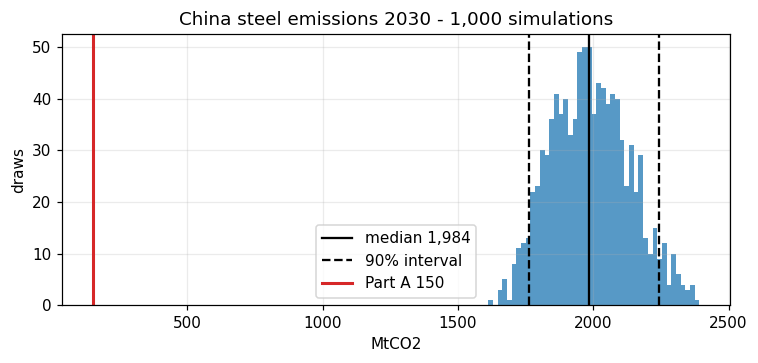

In [15]:
def summarise(draws, label=""):
    lo, med, hi = np.percentile(draws, [5, 50, 95])
    return {"label": label, "median": med, "p5": lo, "p95": hi,
            "rel_half_width": (hi - lo) / (2 * med)}


q8 = summarise(sim2030["national"], "simulation 2030")
partA_2030 = company_emissions.query("Year == 2030")["estimated_emissions_tCO2"].sum() / 1e6

print(f"2030 national emissions, simulation")
print(f"  median              : {q8['median']:,.0f} MtCO2")
print(f"  90% interval        : {q8['p5']:,.0f} - {q8['p95']:,.0f} MtCO2")
print(f"  relative half-width : {q8['rel_half_width']:.1%}")
print(f"\nPart A pipeline 2030 : {partA_2030:,.0f} MtCO2"
      f"   ({q8['median'] / partA_2030:.1f}x smaller than the simulation median)")

fig, ax = plt.subplots(figsize=(7, 3.4))
ax.hist(sim2030["national"], bins=45, color="tab:blue", alpha=0.75)
ax.axvline(q8["median"], color="k", label=f"median {q8['median']:,.0f}")
ax.axvline(q8["p5"], color="k", linestyle="--", label="90% interval")
ax.axvline(q8["p95"], color="k", linestyle="--")
ax.axvline(partA_2030, color="tab:red", linewidth=2, label=f"Part A {partA_2030:,.0f}")
ax.set(title="China steel emissions 2030 - 1,000 simulations", xlabel="MtCO2", ylabel="draws")
ax.legend(); plt.tight_layout(); plt.show()

**Your answer (Q8):**

**(a) 2030 national emissions (1,000 simulations).**
median **1,984 MtCO2**, 90% interval **1,762 - 2,243 MtCO2**,
relative half-width = (2,243 - 1,762) / (2 x 1,984) = **12.1%**.

**(b) Comparison with Part A.** The Part A pipeline gives **150 MtCO2** for 2030 - the simulation
median is **13.2x larger**. The simulation is the one that is in the right place: independent
estimates of China's iron and steel sector sit in the order of 1.5-2 GtCO2 per year, and our median
of ~1,984 MtCO2 corresponds to ~1,073 Mt of crude steel at an average 1.85 tCO2/t, which matches
official output.

They differ so much because of the coverage problem of B1. Part A computes utilisation as
*reported production / total capacity* - but only ~10% of China's production is reported, so the rate
comes out at 0.063 instead of ~0.80. That 10x under-estimate of the **rate** is then applied to the
**whole** fleet, so the error is carried through to every plant and every company. The simulation
uses the **matched** utilisation of B2 (~0.795 for BF-BOF), where numerator and denominator describe
the same plants, so the rate is a real utilisation and the fleet-wide total becomes plausible.
Part A's number is not "a bit low" - it answers a different question: it is roughly the emissions of
the plants that happen to report, not of China.


### Q9 [QUANT + QUAL] Which input matters most?

Run `simulate` twice: once varying **only the utilisation** (`vary_ef=False`) and once varying **only the emission factor** (`vary_util=False`). For each, give the relative half-width for 2030. Which input creates more of the uncertainty? Could **more data** reduce it?

In [16]:
q9 = pd.DataFrame([
    summarise(simulate(1000, 2030, vary_ef=False, seed=SEED)["national"], "utilisation only"),
    summarise(simulate(1000, 2030, vary_util=False, seed=SEED)["national"], "emission factor only"),
    summarise(sim2030["national"], "both"),
]).set_index("label")
with pd.option_context("display.float_format", "{:,.3f}".format):
    display(q9)
print(f"the emission factor contributes "
      f"{q9.loc['emission factor only', 'rel_half_width'] / q9.loc['utilisation only', 'rel_half_width']:.1f}x "
      f"more relative width than the utilisation")

,median,p5,p95,rel_half_width
label,,,,
utilisation only,"1,948.090","1,858.803","2,021.436",0.042
emission factor only,"1,986.330","1,778.978","2,229.263",0.113
both,"1,983.611","1,762.380","2,242.587",0.121


the emission factor contributes 2.7x more relative width than the utilisation


**Your answer (Q9):**

| varying | median (MtCO2) | 90% interval | relative half-width |
|---|---|---|---|
| utilisation only (`vary_ef=False`) | 1,948 | 1,859 - 2,021 | **4.2%** |
| emission factor only (`vary_util=False`) | 1,986 | 1,779 - 2,229 | **11.3%** |
| both | 1,984 | 1,762 - 2,243 | 12.1% |

**The emission factor dominates** - on its own it reproduces 11.3 of the 12.1 percentage points of
the full interval, **2.7x more** than the utilisation. (The two add roughly in quadrature:
sqrt(4.2^2 + 11.3^2) = 12.1, exactly what we get, which confirms the two inputs are independent in
the model.)

**Could more data reduce it?** Yes - the emission-factor uncertainty is **epistemic**. Each plant has
a true CO2 intensity determined by its fuel mix, scrap ratio, on-site power and ore quality;
plant-level energy and material balances, audited company disclosures, or continuous emission
monitoring would replace the 0.85-1.20 (BF-BOF) and 0.65-2.00 (EAF) guess ranges with measured values
and could shrink this component by most of its width. The utilisation component would also shrink if
more plants reported (it is the bootstrap of 59 plants), but it is already the smaller half.

One honest caveat: these triangular ranges are **assumed illustrative values given in the lab**, not
estimated from data - so the 11.3% is itself a modelling choice. The right reading is "the emission
factor is where the money is: spend the next data-collection euro there", not "the uncertainty is
exactly 11.3%".


### Q10 [QUANT + QUAL] Companies: can you say who is number one?

Using `by_company` of your 2030 run: (a) for the **top 3 companies by median**, give the median and the 90% interval; (b) compute the probability that the #1 company emits **more than** the #2 (fraction of simulations); (c) what would you write in a report instead of "Company X is the largest emitter"?

,median,p5,p95,rel_half_width
Angang Steel Co Ltd [100.0%],55.60,49.29,63.06,0.12
Baoshan Iron & Steel Co Ltd [100.0%],52.41,46.46,59.44,0.12
Jinghua Rigang Holding Group Co Ltd [98.8%]; unknown [1.2%],38.22,33.88,43.34,0.12


P(#1 'Angang Steel Co Ltd [100.0%]...' > #2) = 1.000
do their 90% intervals overlap? True


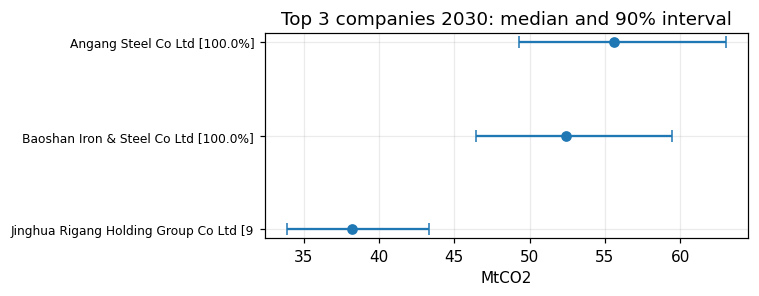

In [17]:
by_company = sim2030["by_company"]
top3 = by_company.median().nlargest(3)

q10 = pd.DataFrame({"median": top3,
                    "p5": by_company[top3.index].quantile(0.05),
                    "p95": by_company[top3.index].quantile(0.95)})
q10["rel_half_width"] = (q10["p95"] - q10["p5"]) / (2 * q10["median"])
display(q10)

first, second = top3.index[0], top3.index[1]
p_first_bigger = (by_company[first] > by_company[second]).mean()
overlap = (q10.loc[first, "p5"] < q10.loc[second, "p95"])
print(f"P(#1 '{first[:40]}...' > #2) = {p_first_bigger:.3f}")
print(f"do their 90% intervals overlap? {overlap}")

fig, ax = plt.subplots(figsize=(7, 2.8))
ypos = np.arange(3)[::-1]
ax.errorbar(q10["median"], ypos,
            xerr=[q10["median"] - q10["p5"], q10["p95"] - q10["median"]],
            fmt="o", capsize=4)
ax.set_yticks(ypos); ax.set_yticklabels([c[:38] for c in q10.index], fontsize=8)
ax.set(title="Top 3 companies 2030: median and 90% interval", xlabel="MtCO2")
plt.tight_layout(); plt.show()

**Your answer (Q10):**

**(a) Top 3 by median, 2030 (MtCO2).**

| company | median | 90% interval | relative half-width |
|---|---|---|---|
| Angang Steel Co Ltd [100.0%] | **55.6** | 49.3 - 63.1 | 12.4% |
| Baoshan Iron & Steel Co Ltd [100.0%] | **52.4** | 46.5 - 59.4 | 12.4% |
| Jinghua Rigang Holding Group Co Ltd [98.8%]; unknown [1.2%] | **38.2** | 33.9 - 43.3 | 12.4% |

**(b) P(#1 > #2) = 1.000** in 1,000 simulations - even though the two 90% intervals overlap over
almost their whole length (49.3-63.1 vs 46.5-59.4).

That combination looks contradictory, and the reason is important: in this model **every company is
hit by the same draws**. There is one utilisation draw and one emission-factor multiplier per
technology per simulation, applied to all plants at once, so Angang and Baoshan move up and down
together and their *ratio* is almost constant. The uncertainty we have quantified is entirely
**common-mode (systematic)**; we have modelled no plant-specific or company-specific error -
no error in each plant's capacity, in its equipment classification, or in which parent owns it.
Those are precisely the errors that would reorder the ranking, and the overlapping intervals are the
honest signal: the 3.2 MtCO2 gap between #1 and #2 is less than half the +/-7 MtCO2 uncertainty on
either of them.

**(c) What to write in a report instead of "Company X is the largest emitter":**

> "Under our assumptions, Angang Steel and Baoshan Iron & Steel are the two largest emitters in our
> 2030 estimate, at about 56 MtCO2 (90%: 49-63) and 52 MtCO2 (90%: 46-59). The two are within 6% of
> each other and their ranges overlap almost entirely, so **we cannot say which of them is actually
> number one**. The apparent certainty of the ranking is an artefact of the model, which moves all
> companies together; it does not survive the ownership and capacity uncertainty we have not
> quantified. What we can say is that these two are clearly ahead of the rest of the field."


## B5. Is the interval honest? Test it

A 90% interval should contain the true value in about 90% of cases. We have one case where the truth is known: **official 2023 production**.

### Q11 [QUANT + QUAL] Does the official value fall inside?

Run `simulate(1000, year=2023)` and look at `national_prod` (Mt). (a) Give its 90% interval and say whether the official 2023 value (1,020 Mt) falls inside. (b) If not, what does this tell you about the interval, **even though it was computed correctly**? (c) What would you do about it?

simulated 2023 production: median 1,082 Mt, 90% interval 1,028 - 1,126 Mt
official 2023 (worldsteel): 1,020 Mt  ->  inside the interval? False
the interval sits +6.0% above the official value at the median; the lower bound is +0.7% away

fleet definition check, 2023: all capacity 1,386 Mt -> 1,102 Mt of steel
                             operating only 1,088 Mt -> 865 Mt of steel   (official: 1,020 Mt)


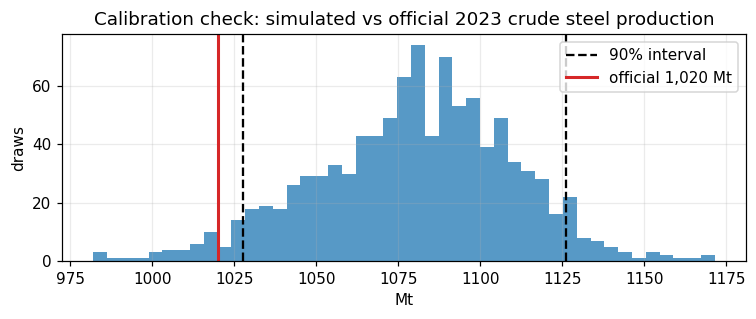

In [18]:
sim2023 = simulate(1000, year=2023, seed=SEED)
lo, med, hi = np.percentile(sim2023["national_prod"], [5, 50, 95])
official_2023 = official_mt[2023]
inside = lo <= official_2023 <= hi

print(f"simulated 2023 production: median {med:,.0f} Mt, 90% interval {lo:,.0f} - {hi:,.0f} Mt")
print(f"official 2023 (worldsteel): {official_2023:,} Mt  ->  inside the interval? {inside}")
print(f"the interval sits {med / official_2023 - 1:+.1%} above the official value at the median; "
      f"the lower bound is {lo / official_2023 - 1:+.1%} away")

# How much of the gap comes from counting non-operating capacity? (used in Q11c)
_d = china_operational[china_operational["Year"] == 2023]
_op = _d[_d["Status"].isin(OPERATING_STATUS)][CAP].sum()
print(f"\nfleet definition check, 2023: all capacity {_d[CAP].sum() / 1000:,.0f} Mt "
      f"-> {_d[CAP].sum() / 1000 * pooled_matched_u['BF-BOF']:,.0f} Mt of steel")
print(f"                             operating only {_op / 1000:,.0f} Mt "
      f"-> {_op / 1000 * pooled_matched_u['BF-BOF']:,.0f} Mt of steel   (official: 1,020 Mt)")

fig, ax = plt.subplots(figsize=(7, 3.0))
ax.hist(sim2023["national_prod"], bins=45, alpha=0.75)
ax.axvline(lo, color="k", linestyle="--"); ax.axvline(hi, color="k", linestyle="--", label="90% interval")
ax.axvline(official_2023, color="tab:red", linewidth=2, label=f"official {official_2023:,} Mt")
ax.set(title="Calibration check: simulated vs official 2023 crude steel production",
       xlabel="Mt", ylabel="draws"); ax.legend()
plt.tight_layout(); plt.show()

**Your answer (Q11):**

**(a)** `simulate(1000, year=2023)` gives a 2023 production median of **1,082 Mt** with a 90% interval
of **1,028 - 1,126 Mt**. The official worldsteel figure of **1,020 Mt** falls **outside** the interval -
just below it: the median is 6.0% too high and the lower bound still misses by 0.7%.

**(b) What it tells us.** The arithmetic is right; the **model** is wrong. A 90% interval should miss
the truth about one time in ten, and the one case where we know the truth is a miss. The interval
propagates only the two uncertainties we chose to model - the sampling error of utilisation and an
assumed emission-factor range - and it ignores **structural (model) uncertainty**:

* the fleet is too big: 21-29% of the capacity we multiply carries a non-operating `Status` (Q1), and
  retired plants with an `unknown` retirement date never leave;
* the utilisation we apply is measured on the plants that report, which are the better-run ones
  (Q6b), so it is biased high;
* capacity, equipment classification and the start/retire dates are all taken as exact.

In other words it is a **precise answer to the wrong question**: a narrow interval around a biased
centre. Statistical precision is not accuracy, and a model that is internally consistent can still be
confidently wrong.

**(c) What we would do about it.**
1. **Fix the fleet definition, but calibrate it - do not just guess.** Restricting the 2023 fleet to
   `operating` / `operating pre-retirement` capacity (1,088 Mt instead of 1,386 Mt) would give ~865 Mt
   of production at u = 0.795 - now **below** the official 1,020 Mt. Neither definition is right, so
   the inclusion rule itself (e.g. a share of mothballed and pre-retirement capacity) should be
   estimated by making the model reproduce 2020-2023 official output.
2. **Add a structural-error term.** Back-test against all four official years, take the residual
   bias and spread, and carry them forward as an extra multiplicative uncertainty on 2030 - our
   interval would then be centred correctly and roughly twice as wide.
3. **Report the back-test.** Publish the coverage of the interval ("it contained the known value in
   0 of 4 years") next to the interval itself, so the reader knows the 90% is nominal, not earned.


## B6. Scenarios

A **scenario** is a "what if" story. We do **not** attach a probability to it; we run each one through the same simulation and compare.

| Scenario | Story | How |
|---|---|---|
| **S0** | no change | as is |
| **S1** | **30% of BF-BOF capacity is retired** (by 2027, still true in 2030) | `bf_cap_mult=0.7` |
| **S2** | **steel demand drops**: utilisation 10% lower | `util_mult=0.9` |

### Q12 [QUANT + QUAL] Scenario gap vs interval width

(a) Run the three scenarios for 2030 and give the **median and 90% interval** of each. (b) Compare the **gap between** scenario medians with the **width of the interval** within a scenario. Which is bigger? (c) Why would it be misleading to average the three scenarios into one probability-weighted number?

,median,p5,p95,rel_half_width,width
label,,,,,
S0 - no change,"1,983.61","1,762.38","2,242.59",0.12,480.21
S1 - 30% of BF-BOF retired,"1,409.32","1,255.59","1,591.69",0.12,336.10
S2 - demand -10%,"1,785.25","1,586.14","2,018.33",0.12,432.19


gap S0-S1 between medians : 574 MtCO2
gap S0-S2 between medians : 198 MtCO2
width of the 90% interval inside S0: 480 MtCO2


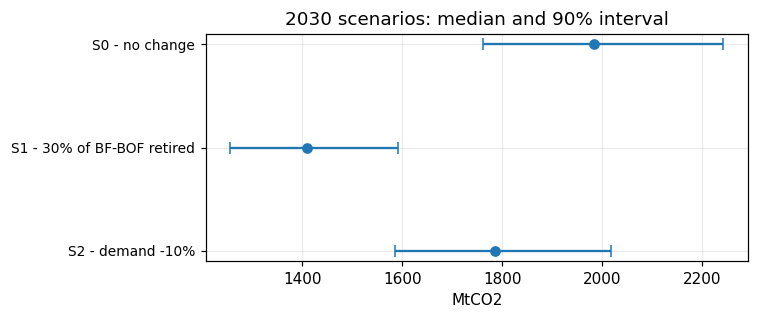

In [19]:
scenarios = {"S0 - no change":            dict(),
             "S1 - 30% of BF-BOF retired": dict(bf_cap_mult=0.7),
             "S2 - demand -10%":           dict(util_mult=0.9)}

sim_scen = {name: simulate(1000, 2030, seed=SEED, **kw) for name, kw in scenarios.items()}
q12 = pd.DataFrame([summarise(s["national"], name) for name, s in sim_scen.items()]).set_index("label")
q12["width"] = q12["p95"] - q12["p5"]
with pd.option_context("display.float_format", "{:,.2f}".format):
    display(q12)

gap_S0_S1 = q12.loc["S0 - no change", "median"] - q12.loc["S1 - 30% of BF-BOF retired", "median"]
gap_S0_S2 = q12.loc["S0 - no change", "median"] - q12.loc["S2 - demand -10%", "median"]
print(f"gap S0-S1 between medians : {gap_S0_S1:,.0f} MtCO2")
print(f"gap S0-S2 between medians : {gap_S0_S2:,.0f} MtCO2")
print(f"width of the 90% interval inside S0: {q12.loc['S0 - no change', 'width']:,.0f} MtCO2")

fig, ax = plt.subplots(figsize=(7, 3.0))
ypos = np.arange(len(q12))[::-1]
ax.errorbar(q12["median"], ypos, xerr=[q12["median"] - q12["p5"], q12["p95"] - q12["median"]],
            fmt="o", capsize=4)
ax.set_yticks(ypos); ax.set_yticklabels(q12.index, fontsize=9)
ax.set(title="2030 scenarios: median and 90% interval", xlabel="MtCO2")
plt.tight_layout(); plt.show()

**Your answer (Q12):**

**(a) 2030, 1,000 simulations per scenario (MtCO2).**

| scenario | median | 90% interval | width |
|---|---|---|---|
| **S0** no change | **1,984** | 1,762 - 2,243 | 480 |
| **S1** 30% of BF-BOF capacity retired | **1,409** | 1,256 - 1,592 | 336 |
| **S2** steel demand -10% (utilisation x 0.9) | **1,785** | 1,586 - 2,018 | 432 |

**(b) Scenario gap vs interval width.**
* S0 - S1 = **574 MtCO2**, which is **larger** than the 480 MtCO2 width of the interval inside S0 -
  and the two intervals (1,762-2,243 and 1,256-1,592) do not overlap at all. This difference is real:
  it survives everything we can measure.
* S0 - S2 = **198 MtCO2**, which is **less than half** the interval width, and the two intervals
  overlap over almost their whole length. This difference is **not** resolvable by our model.

The conclusion is a decision-useful one: **the policy choice about blast-furnace capacity matters more
than all of our measurement uncertainty put together, while a 10% swing in demand is lost inside it.**
A bank should spend its effort tracking retirement announcements, not refining its demand forecast.

**(c) Why not average the three into one probability-weighted number?** Because the weights would be
invented. S1 and S2 are not random events with frequencies - they are the outcomes of decisions
(Chinese industrial policy, construction demand) that have not been taken yet, so no probability
exists to be estimated; writing 1/3 each would dress up a political judgement as a statistic. A
weighted average also produces a number (around 1,730 MtCO2) that **no scenario actually predicts**,
it sits in a region every single scenario considers unlikely, and it destroys the only useful piece
of information in the table - that one specific decision moves the answer by 0.6 GtCO2. Scenarios are
there to be **compared side by side**, not collapsed.


## B7. Communicate

Words used by the IPCC for probabilities: **virtually certain** 99-100%, **very likely** 90-100%, **likely** 66-100%, **about as likely as not** 33-66%, **unlikely** 10-33%, **very unlikely** 1-10%, **exceptionally unlikely** 0-1%.

### Q13 [QUANT + QUAL] A probability, a word, and a note

(a) For each scenario, compute the probability that **2030 emissions exceed the 2023 median** (from your `simulate(..., year=2023)`) and give the matching word. (b) Write a note of **about 80 words** for a bank's risk committee about China's steel emissions in 2030. Include: the **median and 90% interval** (baseline), **one sentence on the scenarios**, the **biggest source of uncertainty**, **one limitation** of the model and **one recommended action**. Plain language, no jargon.

> **Hint.** `(draws > threshold).mean()`.

In [20]:
IPCC = [(0.99, "virtually certain"), (0.90, "very likely"), (0.66, "likely"),
        (0.33, "about as likely as not"), (0.10, "unlikely"), (0.01, "very unlikely"),
        (0.00, "exceptionally unlikely")]


def ipcc_word(p):
    for threshold, word in IPCC:
        if p >= threshold:
            return word
    return "exceptionally unlikely"


threshold_2023 = np.median(sim2023["national"])
print(f"reference: median of the 2023 simulation = {threshold_2023:,.0f} MtCO2\n")

q13 = pd.DataFrame([{"scenario": name,
                     "median 2030 (MtCO2)": np.median(s["national"]),
                     "P(2030 > 2023 median)": (s["national"] > threshold_2023).mean(),
                     "IPCC wording": ipcc_word((s["national"] > threshold_2023).mean())}
                    for name, s in sim_scen.items()]).set_index("scenario")
display(q13)

reference: median of the 2023 simulation = 2,005 MtCO2



,median 2030 (MtCO2),P(2030 > 2023 median),IPCC wording
scenario,,,
S0 - no change,"1,983.61",0.45,about as likely as not
S1 - 30% of BF-BOF retired,"1,409.32",0.00,exceptionally unlikely
S2 - demand -10%,"1,785.25",0.06,very unlikely


**Your answer (Q13):**

**(a) Probability that 2030 emissions exceed the 2023 median (2,005 MtCO2).**

| scenario | median 2030 | P(2030 > 2023 median) | IPCC wording |
|---|---|---|---|
| S0 - no change | 1,984 | **0.445** | **about as likely as not** |
| S1 - 30% of BF-BOF retired | 1,409 | **0.000** | **exceptionally unlikely** |
| S2 - demand -10% | 1,785 | **0.060** | **very unlikely** |

**(b) Note for the risk committee (~85 words).**

> **China steel emissions, 2030.** Our best estimate is about **1,980 million tonnes of CO2**, with a
> plausible range of **1,760 to 2,240**. On current plans that is roughly the same as today: as likely
> as not, 2030 is no better than 2023. If China retires 30% of its blast-furnace capacity, emissions
> fall to about 1,410; a 10% drop in steel demand changes little. Most of the uncertainty is in how
> much CO2 each tonne of steel creates, not in how much steel is made. **Limitation:** our model
> over-states actual 2023 output by 6%, so treat the level with caution and use the comparison
> between scenarios rather than the absolute figure. **Recommendation:** track announced
> blast-furnace closures quarterly, because that single decision moves the result more than every
> measurement uncertainty we can quantify.
